In [45]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import norm, lognorm, gamma

In [32]:
scores = pd.read_parquet("rugbypass_perf_data.parquet")

In [33]:
def score_common(player): 
    return 10 * player['tries'] \
        + 4 * player['try_assists'] \
        + 2 * player['defenders_beaten'] \
        + player['carries_metres'] // 10 \
        + player['completed_tackles'] \
        + 5 * player['turnovers_won'] \
        + 2 * player['offloads']
scores["score"] = score_common(scores)

In [34]:
df = scores[scores["minutes_played"] > 0]
df["spm"] = scores["score"] / scores["minutes_played"]
df = df[df["spm"] > 0]

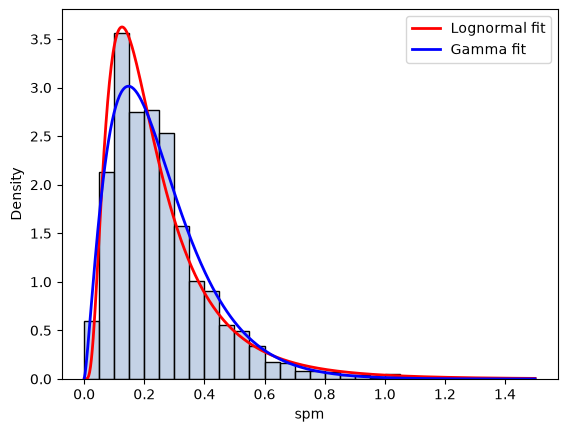

In [63]:
shape, loc, scale = lognorm.fit(df["spm"], floc=0)
g_shape, g_loc, g_scale = gamma.fit(df["spm"], floc=0)

fig, ax = plt.subplots()

sns.histplot(df["spm"], stat="density", bins=30, ax=ax, binrange=(0, 1.5), color="lightsteelblue")

# Plot fitted density
x = np.linspace(0.0, 1.5, 500)
pdf = lognorm.pdf(x, shape, loc=loc, scale=scale)
gamma_pdf = gamma.pdf(x, g_shape, g_loc, g_scale)

ax.plot(x, pdf, color="red", lw=2, label="Lognormal fit")
ax.plot(x, gamma_pdf, color="blue", lw=2, label="Gamma fit")

ax.legend()

In [80]:
player_avgs = df.groupby("name") \
    .filter(lambda g: len(g) > 10) \
    .groupby("name") \
    .apply(lambda g: g["spm"].mean())

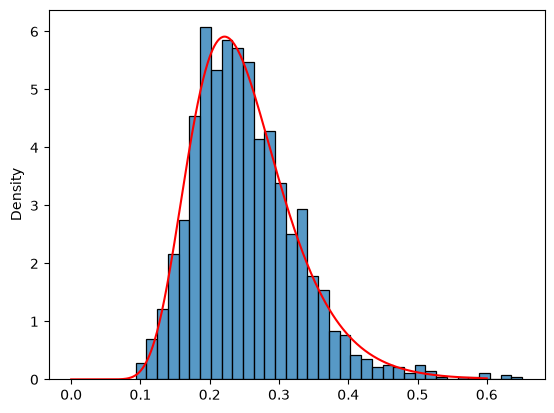

In [81]:
ln_s, ln_loc, ln_shape = lognorm.fit(player_avgs, floc=0.0)

fig, ax = plt.subplots()

sns.histplot(player_avgs, stat="density", ax=ax)

x = np.linspace(0.0, 0.6, 500)
n_pdf = lognorm.pdf(x, ln_s, loc=ln_loc, scale=ln_shape)

ax.plot(x, n_pdf, color="red")

In [85]:
# For now, we assume that the prior (latent ability) is log-normally distributed with these parameters
ln_s, ln_shape

(np.float64(0.29204543822039186), np.float64(0.24118700213268493))

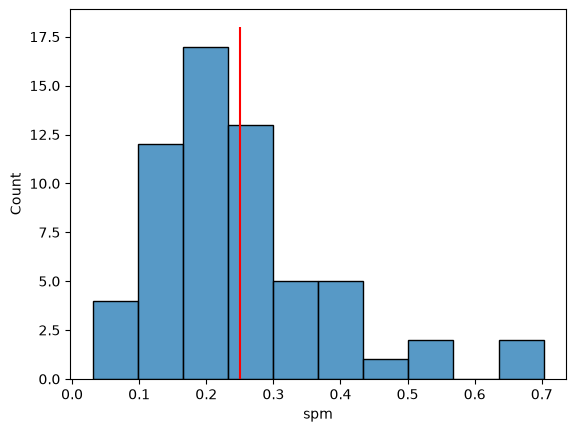

In [106]:
name = "Ellis Genge"

fig, ax = plt.subplots()
sns.histplot(df[df["name"] == name]["spm"], ax=ax)
ax.vlines(player_avgs.loc[name], ymin=0, ymax=18, color="red")

In [125]:
# Variance of spm based vs average minutes played per match
df_mp_spm = pd.DataFrame()
df_mp_spm["avg_mp"] = df.groupby("name") \
    .apply(lambda g: g["minutes_played"].mean())

df_mp_spm["matches_played"] = df.groupby("name") \
    .apply(lambda g: len(g))

df_mp_spm["var"] = df.groupby("name") \
    .apply(lambda g: g["spm"].var())


(0.0, 0.3)

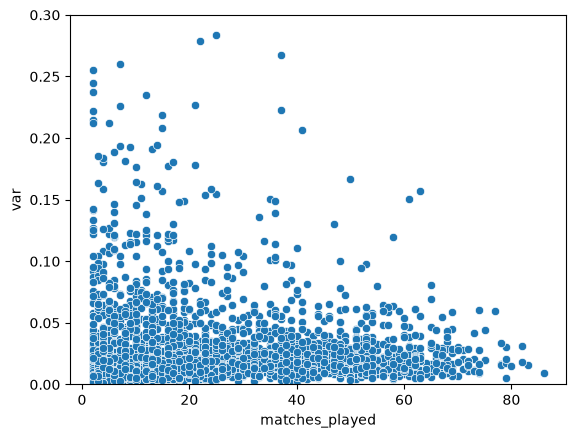

In [133]:
fig, ax = plt.subplots()
sns.scatterplot(df_mp_spm, x="matches_played", y="var", ax=ax)
ax.set_ylim(0.0, 0.3)

name
AJ MacGinty                 17.655172
Aaron Grandidier-Nkanang    14.000000
Aaron Hinkley               15.636364
Aaron Morris                 7.000000
Aaron Sexton                11.333333
                              ...    
Zander Fagerson             12.144928
Zander du Plessis            9.000000
Zee Mkhabela                 2.000000
Zekhethelo Siyaya           36.250000
Zinedine Aouad               7.000000
Length: 2963, dtype: float64

In [157]:
# compute within-player sample variance by pooling
mean_scores = df.groupby("name").apply(lambda g: g["spm"].mean())

def in_player_variance(g): 
    return pd.Series({"matches_played": len(g), "s": ((g["spm"] - mean_scores.loc[g.name])**2).sum() / (len(g) - 1)}, index=["matches_played", "s"])
    
player_vars = df.groupby("name") \
    .filter(lambda g: len(g) >= 2) \
    .groupby("name") \
    .apply(in_player_variance)

sigma_sqr = ((player_vars["matches_played"] - 1)*player_vars["s"]).sum() / (player_vars["matches_played"] - 1).sum()

In [211]:
tau_sqr = lognorm.var(ln_s, loc=ln_loc, scale=ln_shape)

In [290]:
# Now our Bayesian shrinkage estimator uses ln_s, ln_shape and sigma_sqr
player_shrinkages = df.groupby("name") \
    .filter(lambda g: len(g) >= 2) \
    .groupby("name") \
    .apply(lambda g: (g["minutes_played"].sum() / 80)*tau_sqr / ((g["minutes_played"].sum() / 80)*tau_sqr + sigma_sqr))

In [325]:
average_minutes = df.groupby("name").apply(lambda g: g["minutes_played"].mean())

average_pos_minutes = df.groupby("number").apply(lambda g: g["minutes_played"].mean())

expected_scores = pd.DataFrame()
expected_scores["exp_number"] = df.groupby("name").apply(lambda g: g["number"].mode())
expected_scores = expected_scores.join(average_pos_minutes.rename("avg_pos_minutes"), on="exp_number")
expected_scores["exp_spm"] = player_shrinkages * mean_scores + (1 - player_shrinkages) * df["spm"].mean()
expected_scores["exp_score"] = expected_scores["exp_spm"] * expected_scores["avg_pos_minutes"]

In [331]:
expected_scores

,,exp_number,avg_pos_minutes,exp_spm,exp_score
name,,,,,
AJ MacGinty,0,10.0,72.497340,0.309946,22.470287
Aaron Grandidier-Nkanang,0,11.0,74.806591,0.199566,14.928836
Aaron Hinkley,0,7.0,69.380319,0.274244,19.027142
Aaron Morris,0,11.0,74.806591,NaN,NaN
Aaron Sexton,0,11.0,74.806591,0.271019,20.274007
...,...,...,...,...,...
Zander Fagerson,0,3.0,53.818940,0.218147,11.740430
Zander du Plessis,0,23.0,26.909878,0.291994,7.857528
Zee Mkhabela,0,21.0,23.256344,0.241341,5.612710


In [332]:
expected_scores.loc["Arthur Retiere"]

,exp_number,avg_pos_minutes,exp_spm,exp_score
0,11.0,74.806591,0.415674,31.095150
1,14.0,74.391203,0.415674,30.922484


In [327]:
expected_scores["exp_score"][~expected_scores["exp_score"].isna()].sort_values().tail(20)

name                    
Alfie Barbeary         0    28.847317
George Hendy           0    28.871788
Jiuta Wainiqolo        0    28.900141
Scott Penny            0    29.242210
Davit Niniashvili      1    29.267648
                       0    29.275201
Cameron Hanekom        0    29.520082
Mateo Carreras         0    29.598724
Antoine Dupont         0    29.636384
Shamus Hurley-Langton  0    29.660883
Jasper Wiese           0    30.055289
Sean Jansen            0    30.292783
Noah Caluori           0    30.313410
Arthur Retiere         1    30.922484
                       0    31.095150
Xan Mousques           0    32.248862
Tom Willis             0    33.074266
Immanuel Feyi-Waboso   0    34.312466
Beka Gorgadze          0    37.252496
Henry Pollock          0    37.256094
Name: exp_score, dtype: float64

In [341]:
# potential shrinkage underperformance due to valuing each individual spm as the same, even though we should have higher confidence in
# longer minutes played
#
# Even though we now have the total minutes played factoring into our estimates, it still rewards strong substitutes, such as Arthur Retiere who
# averages 48 minutes played over 63 matches
#
# TODO: we should weight spm by the players expected minutes played FOR THE TEAM IN QUESTION (club starter likely won't be national team starter)
df[df["name"] == "Arthur Retiere"]["minutes_played"].mean()

np.float64(47.96825396825397)

<Axes: xlabel='number', ylabel='score'>

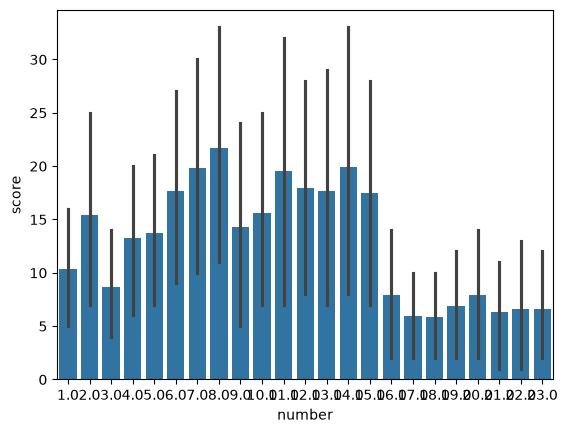

In [265]:
sns.barplot(df, x="number", y="score", errorbar=("pi", 70))

<Axes: xlabel='number', ylabel='minutes_played'>

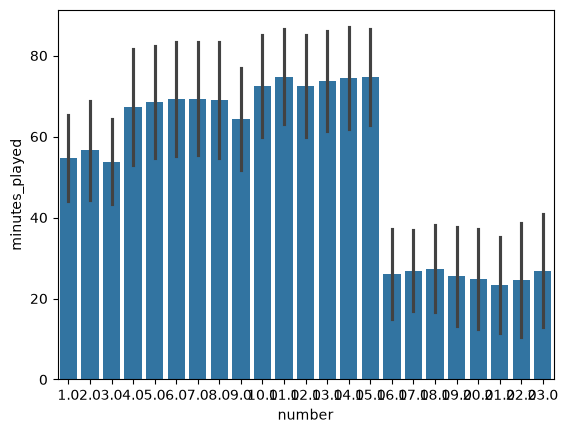

In [248]:
# the playing times are actually quite variable, with averages clearly different between groups (front row, other starters, replacements)
sns.barplot(df, x="number", y="minutes_played", errorbar="sd")

<Axes: xlabel='minutes_played', ylabel='score'>

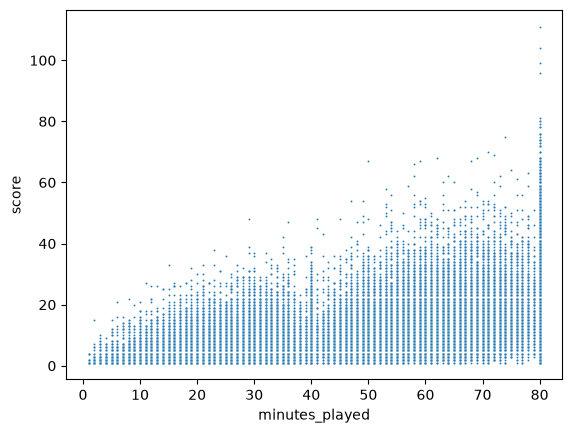

In [356]:
fig, ax = plt.subplots()
df["log_score"] = np.log(df["score"])
df["log_mp"] = np.log(df["minutes_played"])
sns.scatterplot(df, x="minutes_played", y="score", ax=ax, s=2)

<Axes: xlabel='minutes_played'>

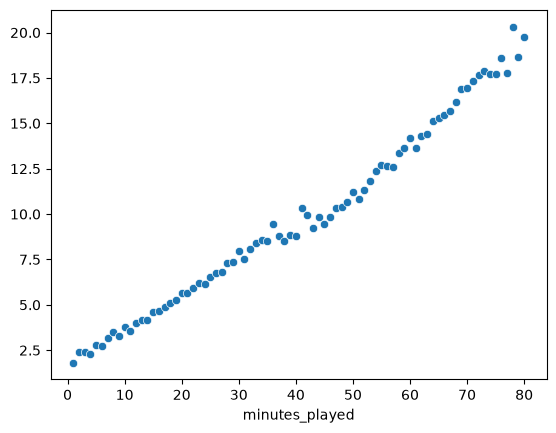

In [357]:
sns.scatterplot(df.groupby("minutes_played").apply(lambda g: g["score"].mean()))